# Visualización de datos con Python: Matplotlib, Seaborn y Plotly

**Objetivo:** representar el mismo conjunto de datos utilizando tres librerías diferentes y observar sus diferencias.

**Contexto:** trabajamos en marketing y queremos analizar los resultados de varias campañas digitales. Los datos son ficticios y están incluidos en el cuaderno: no hace falta subir ningún archivo.

Trabajaremos paso a paso con gráficos de barras, líneas, correlaciones y gráficos interactivos.

## 1. Preparar el entorno

En Google Colab normalmente vienen instaladas las librerías principales. La siguiente celda permite instalar o actualizar las que necesitemos.

In [1]:
%pip -q install matplotlib seaborn plotly pandas

Importamos las librerías. La abreviatura `plt` identifica a Matplotlib, `sns` a Seaborn y `px` a Plotly Express (la interfaz sencilla de Plotly).

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

## 2. Crear nuestros datos

Tenemos seis campañas y sus inversiones, clics y conversiones. Un **DataFrame** de pandas es una tabla con filas y columnas, parecida a una hoja de cálculo.

Calculamos también una nueva columna: **tasa de conversión (%) = conversiones / clics × 100**.

In [3]:
df = pd.DataFrame({
    "campaña": ["Redes A", "Redes B", "Buscador A", "Buscador B", "Email A", "Email B"],
    "canal": ["Redes", "Redes", "Buscador", "Buscador", "Email", "Email"],
    "inversion_eur": [850, 1100, 1600, 1350, 400, 550],
    "clics": [3200, 3800, 4100, 3600, 1700, 2100],
    "conversiones": [96, 137, 205, 162, 119, 147]
})
df["tasa_conversion"] = (df["conversiones"] / df["clics"] * 100).round(2)
df

,campaña,canal,inversion_eur,clics,conversiones,tasa_conversion
0,Redes A,Redes,850,3200,96,3.00
1,Redes B,Redes,1100,3800,137,3.61
2,Buscador A,Buscador,1600,4100,205,5.00
3,Buscador B,Buscador,1350,3600,162,4.50
4,Email A,Email,400,1700,119,7.00
5,Email B,Email,550,2100,147,7.00


## 3. Matplotlib: gráficos básicos

**¿Para qué sirve?** Para controlar cómo se dibuja un gráfico: título, ejes, colores y etiquetas.

### 3.1 Gráfico de barras
Cada barra representa el número de conversiones de una campaña.

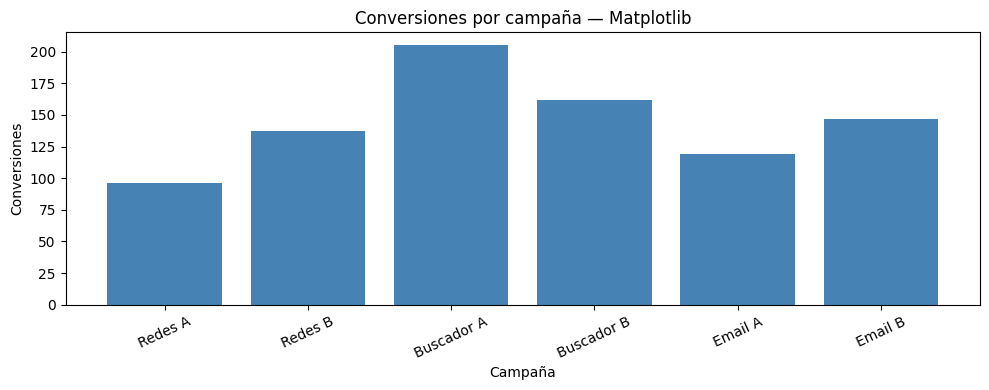

In [13]:
plt.figure(figsize=(10, 4))
plt.bar(df["campaña"], df["conversiones"], color="steelblue")
plt.title("Conversiones por campaña — Matplotlib")
plt.xlabel("Campaña")
plt.ylabel("Conversiones")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

### 3.2 Gráfico de líneas
Podemos representar la evolución mensual de las visitas a una web. **Aquí usamos una segunda tabla** porque ahora nos interesa el tiempo.

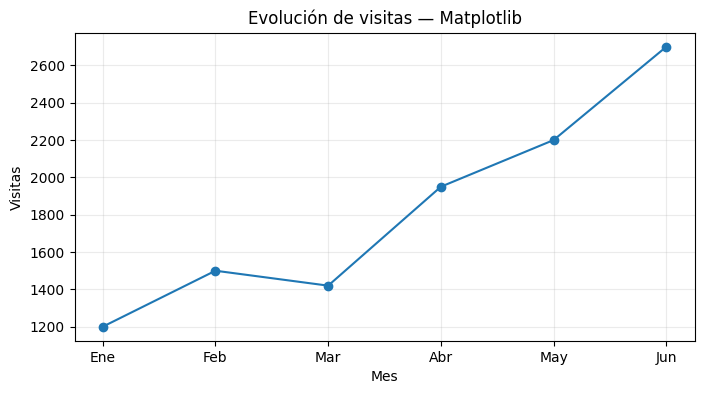

In [17]:
visitas = pd.DataFrame({
    "mes": ["Ene", "Feb", "Mar", "Abr", "May", "Jun"],
    "visitas": [1200, 1500, 1420, 1950, 2200, 2700]
})
plt.figure(figsize=(8, 4))
plt.plot(visitas["mes"], visitas["visitas"], marker="o")
plt.title("Evolución de visitas — Matplotlib")
plt.xlabel("Mes")
plt.ylabel("Visitas")
plt.grid(alpha=0.25)
plt.show()

## 4. Seaborn: relaciones y estadística

**¿Para qué sirve?** Seaborn simplifica la visualización estadística, especialmente cuando tenemos columnas que clasifican los datos en grupos.

### 4.1 Gráfico de barras agrupado por canal
Seaborn utiliza directamente el DataFrame y asigna colores según el canal.

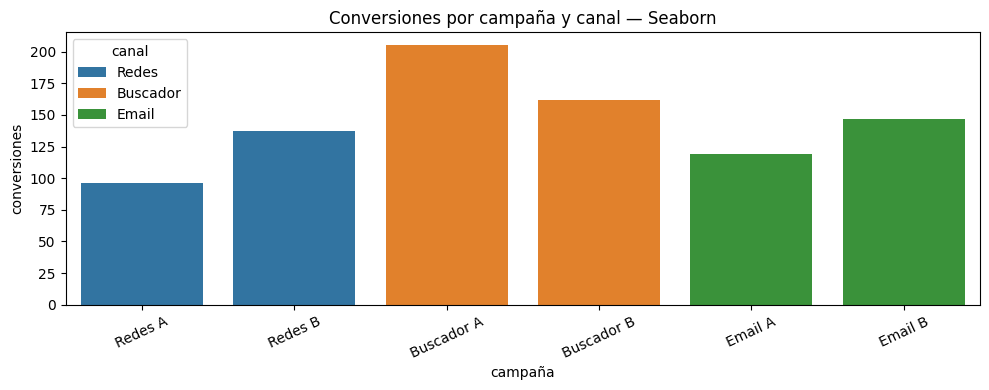

In [6]:
plt.figure(figsize=(10, 4))
sns.barplot(data=df, x="campaña", y="conversiones", hue="canal", dodge=False)
plt.title("Conversiones por campaña y canal — Seaborn")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

### 4.2 Gráfico de dispersión
Cada punto representa una campaña. Sirve para explorar si **invertir más** parece estar relacionado con **obtener más conversiones**.

Ojo: encontrar una relación visual **no demuestra causalidad**.

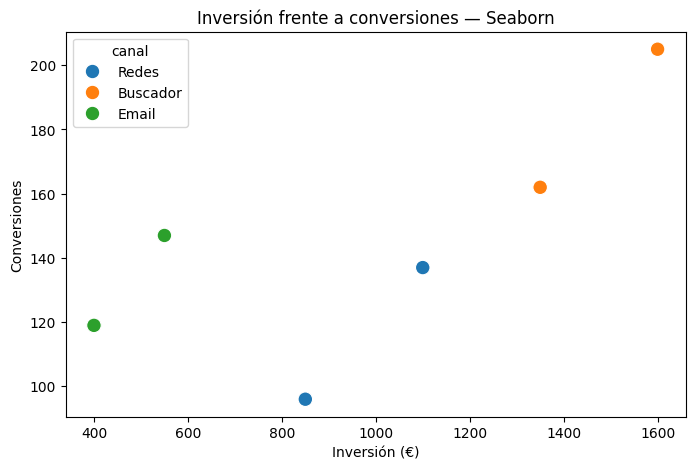

In [7]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="inversion_eur", y="conversiones", hue="canal", s=110)
plt.title("Inversión frente a conversiones — Seaborn")
plt.xlabel("Inversión (€)")
plt.ylabel("Conversiones")
plt.show()



### 4.3 Matriz de correlaciones
La correlación resume cuánto varían juntas dos variables numéricas. Sus valores van de **−1 a 1**. Con solo seis campañas, este ejemplo es didáctico, no permite obtener conclusiones fiables.

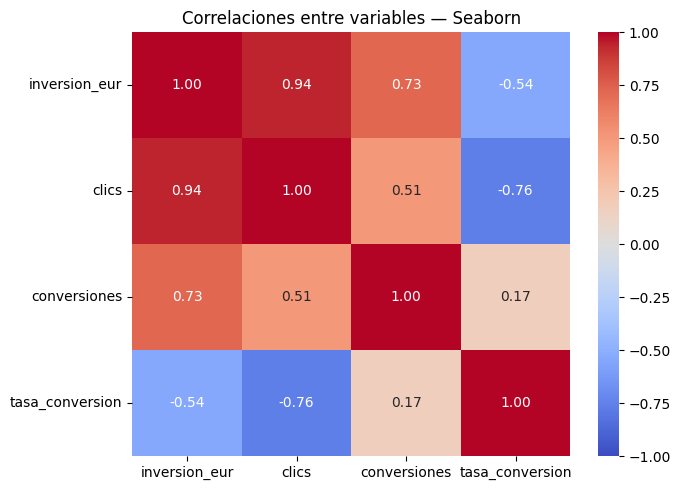

In [8]:
numericas = df[["inversion_eur", "clics", "conversiones", "tasa_conversion"]]
correlaciones = numericas.corr()
plt.figure(figsize=(7, 5))
sns.heatmap(correlaciones, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlaciones entre variables — Seaborn")
plt.tight_layout()
plt.show()

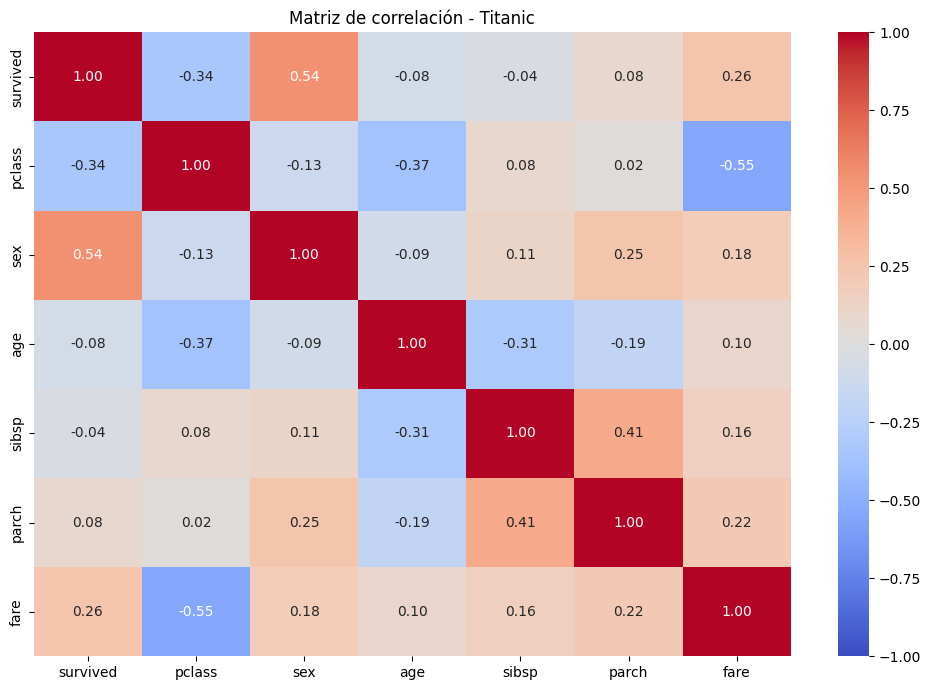

In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("titanic")
df["sex"] = df["sex"].map({"male": 0, "female": 1})
df_numerico = df.select_dtypes(include=["number"])
correlacion = df_numerico.corr()
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlacion,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Matriz de correlación - Titanic")
plt.tight_layout()
plt.show()

## 5. Plotly: gráficos interactivos

**¿Qué lo diferencia?** Con Plotly, podemos pasar el cursor para ver valores, hacer zoom y explorar los datos sin escribir una interfaz web.

### 5.1 Barras interactivas
Repetimos el gráfico de barras con los mismos datos de la sección Matplotlib.

In [9]:
fig = px.bar(df, x="campaña", y="conversiones", color="canal",
             title="Conversiones por campaña — Plotly",
             hover_data=["inversion_eur", "clics", "tasa_conversion"])
fig.show()

### 5.2 Dispersión interactiva
El tamaño de cada burbuja representa los clics de la campaña, el color representa el canal y el cursor muestra más detalles.

In [10]:
fig = px.scatter(df, x="inversion_eur", y="conversiones",
                 color="canal", size="clics", hover_name="campaña",
                 hover_data=["tasa_conversion"],
                 title="Inversión, conversiones y clics — Plotly",
                 labels={"inversion_eur": "Inversión (€)", "conversiones": "Conversiones"})
fig.show()

## 6. Comparar las tres librerías

| Librería | Punto fuerte | Usos habituales |
|---|---|---|
| **Matplotlib** | Control de gráficos estáticos | Informes, artículos, gráficos básicos |
| **Seaborn** | Gráficos estadísticos con poco código | Exploración de datos, relaciones entre variables |
| **Plotly** | Interactividad en el propio notebook | Presentaciones, exploración interactiva, dashboards |

**Idea clave:** no son rivales excluyentes. Podemos usarlas juntas en un mismo proyecto.

**Para conectar con IA:** antes de entrenar un modelo solemos explorar nuestros datos, ver distribuciones, buscar valores extraños y estudiar relaciones. Estos gráficos ayudan a hacerlo.

**Siguiente paso posible:** usar Streamlit para presentar los resultados como una aplicación web independiente, con filtros y botones.